In [ ]:
pip install pandas numpy matplotlib seaborn scikit-learn scipy joblib streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 51.9 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
import joblib
import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving ratings.csv to ratings.csv


In [ ]:
df=pd.read_csv('/content/ratings.csv')
df

,AKM1MP6P0OYPR,0132793040,5.0,1365811200
0,A2CX7LUOHB2NDG,0321732944,5.0,1341100800
1,A2NWSAGRHCP8N5,0439886341,1.0,1367193600
2,A2WNBOD3WNDNKT,0439886341,3.0,1374451200
3,A1GI0U4ZRJA8WN,0439886341,1.0,1334707200
4,A1QGNMC6O1VW39,0511189877,5.0,1397433600
...,...,...,...,...
7824476,A2YZI3C9MOHC0L,BT008UKTMW,5.0,1396569600
7824477,A322MDK0M89RHN,BT008UKTMW,5.0,1313366400
7824478,A1MH90R0ADMIK0,BT008UKTMW,4.0,1404172800
7824479,A10M2KEFPEQDHN,BT008UKTMW,4.0,1297555200


In [ ]:
df.head(10)

,AKM1MP6P0OYPR,0132793040,5.0,1365811200
0,A2CX7LUOHB2NDG,0321732944,5.0,1341100800
1,A2NWSAGRHCP8N5,0439886341,1.0,1367193600
2,A2WNBOD3WNDNKT,0439886341,3.0,1374451200
3,A1GI0U4ZRJA8WN,0439886341,1.0,1334707200
4,A1QGNMC6O1VW39,0511189877,5.0,1397433600
5,A3J3BRHTDRFJ2G,0511189877,2.0,1397433600
6,A2TY0BTJOTENPG,0511189877,5.0,1395878400
7,A34ATBPOK6HCHY,0511189877,5.0,1395532800
8,A89DO69P0XZ27,0511189877,5.0,1395446400
9,AZYNQZ94U6VDB,0511189877,5.0,1401321600


In [ ]:
df.tail(10)

,AKM1MP6P0OYPR,0132793040,5.0,1365811200
7824471,A5FUA9HEV2O42,BT008UKTMW,5.0,1405987200
7824472,A84WRQR47OOKR,BT008UKTMW,1.0,1401753600
7824473,A180UGKKYCPDH0,BT008UKTMW,5.0,1369353600
7824474,A2R6Q6KJCYSVH7,BT008UKTMW,3.0,1343520000
7824475,A2IGIIABRZ5LAB,BT008UKTMW,5.0,1356739200
7824476,A2YZI3C9MOHC0L,BT008UKTMW,5.0,1396569600
7824477,A322MDK0M89RHN,BT008UKTMW,5.0,1313366400
7824478,A1MH90R0ADMIK0,BT008UKTMW,4.0,1404172800
7824479,A10M2KEFPEQDHN,BT008UKTMW,4.0,1297555200
7824480,A2G81TMIOIDEQQ,BT008V9J9U,5.0,1312675200


In [ ]:
df.shape

(7824481, 4)

In [ ]:
df.size

31297924

In [ ]:
df.columns

Index(['AKM1MP6P0OYPR', '0132793040', '5.0', '1365811200'], dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7824481 entries, 0 to 7824480
Data columns (total 4 columns):
 #   Column         Dtype  
---  ------         -----  
 0   AKM1MP6P0OYPR  object 
 1   0132793040     object 
 2   5.0            float64
 3   1365811200     int64  
dtypes: float64(1), int64(1), object(2)
memory usage: 238.8+ MB


In [ ]:
df.isnull().sum()

,0
AKM1MP6P0OYPR,0
0132793040,0
5.0,0
1365811200,0


In [ ]:
df.describe()

,5.0,1365811200
count,7.824481e+06,7.824481e+06
mean,4.012337e+00,1.338178e+09
std,1.380910e+00,6.900426e+07
min,1.000000e+00,9.127296e+08
25%,3.000000e+00,1.315354e+09
50%,5.000000e+00,1.361059e+09
75%,5.000000e+00,1.386115e+09
max,5.000000e+00,1.406074e+09


In [ ]:
df.duplicated().sum()

np.int64(0)

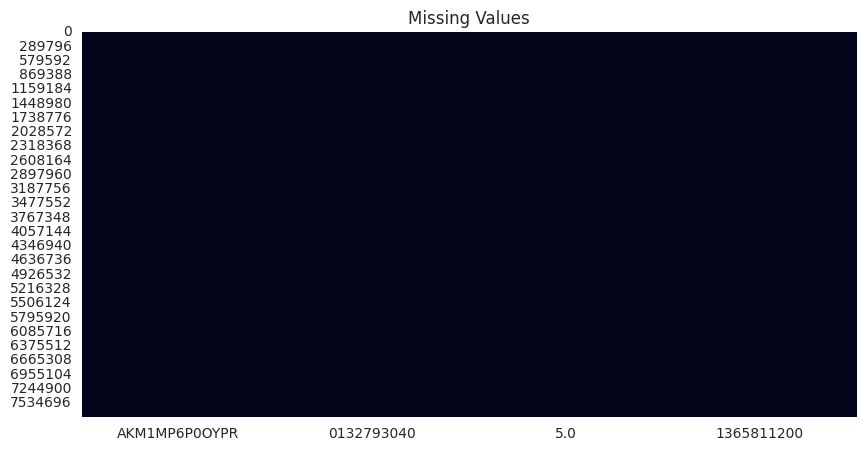

In [ ]:
plt.figure(figsize=(10,5))
sns.heatmap(
    df.isnull(),
    cbar=False
)
plt.title("Missing Values")
plt.show()

In [ ]:
 df.duplicated().sum()

np.int64(0)

In [ ]:
df = df.drop_duplicates()
df

,AKM1MP6P0OYPR,0132793040,5.0,1365811200
0,A2CX7LUOHB2NDG,0321732944,5.0,1341100800
1,A2NWSAGRHCP8N5,0439886341,1.0,1367193600
2,A2WNBOD3WNDNKT,0439886341,3.0,1374451200
3,A1GI0U4ZRJA8WN,0439886341,1.0,1334707200
4,A1QGNMC6O1VW39,0511189877,5.0,1397433600
...,...,...,...,...
7824476,A2YZI3C9MOHC0L,BT008UKTMW,5.0,1396569600
7824477,A322MDK0M89RHN,BT008UKTMW,5.0,1313366400
7824478,A1MH90R0ADMIK0,BT008UKTMW,4.0,1404172800
7824479,A10M2KEFPEQDHN,BT008UKTMW,4.0,1297555200


In [ ]:
df.columns = ['userId', 'productId', 'rating', 'timestamp']
df = df.drop("timestamp", axis=1)
print(df.head())

           userId   productId  rating
0  A2CX7LUOHB2NDG  0321732944     5.0
1  A2NWSAGRHCP8N5  0439886341     1.0
2  A2WNBOD3WNDNKT  0439886341     3.0
3  A1GI0U4ZRJA8WN  0439886341     1.0
4  A1QGNMC6O1VW39  0511189877     5.0


In [ ]:
print("Number of users:", df["userId"].nunique())
print("Number of products:", df["productId"].nunique())

Number of users: 4201696
Number of products: 476001


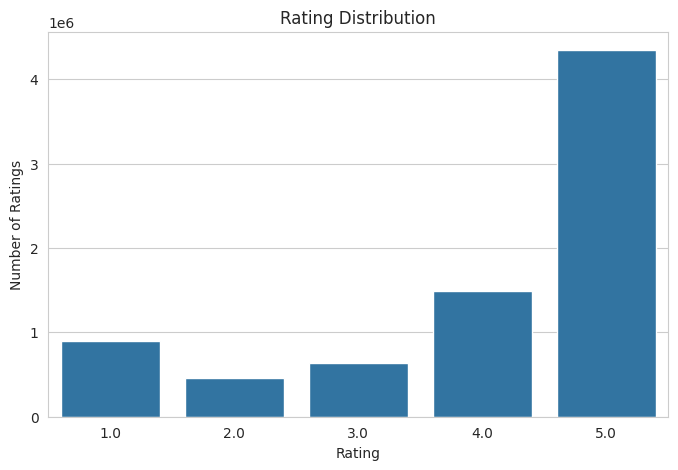

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(
    data=df,
    x="rating"
)
plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.show()

In [ ]:
average_rating = df["rating"].mean()
print("Average Rating:", average_rating)

Average Rating: 4.012336664885505


In [ ]:
user_rating_count = (
    df.groupby("userId")
      .size()
      .sort_values(ascending=False)
)
print(user_rating_count.head(10))

userId
A5JLAU2ARJ0BO     520
ADLVFFE4VBT8      501
A3OXHLG6DIBRW8    498
A6FIAB28IS79      431
A680RUE1FDO8B     406
A1ODOGXEYECQQ8    380
A36K2N527TXXJN    314
A2AY4YUOX2N1BQ    311
AWPODHOB4GFWL     308
A25C2M3QF9G7OQ    296
dtype: int64


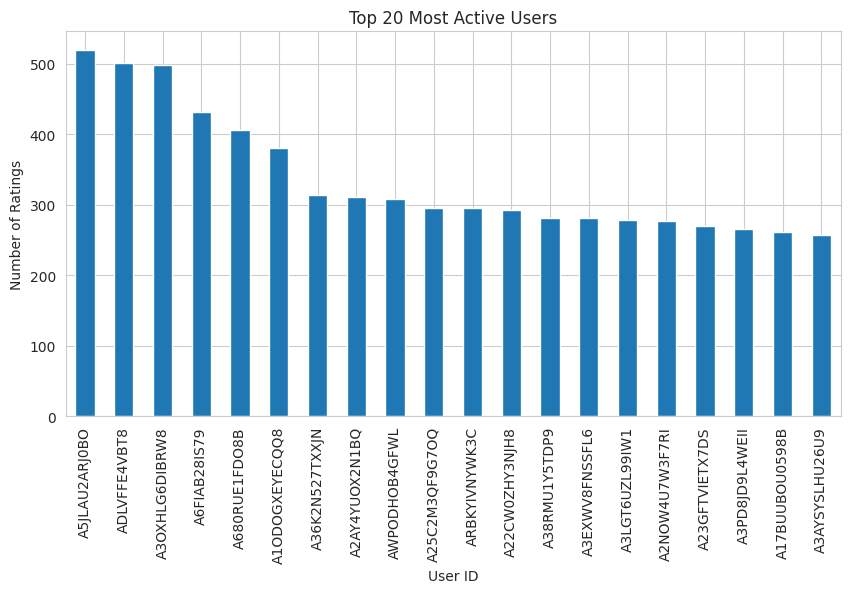

In [ ]:
plt.figure(figsize=(10,5))
user_rating_count.head(20).plot(kind="bar")
plt.title("Top 20 Most Active Users")
plt.xlabel("User ID")
plt.ylabel("Number of Ratings")
plt.show()

In [ ]:
product_rating_count = (
    df.groupby("productId")
      .size()
      .sort_values(ascending=False)
)
print(product_rating_count.head(10))

productId
B0074BW614    18244
B00DR0PDNE    16454
B007WTAJTO    14172
B0019EHU8G    12285
B006GWO5WK    12226
B003ELYQGG    11617
B003ES5ZUU    10276
B007R5YDYA     9907
B00622AG6S     9823
B0002L5R78     9487
dtype: int64


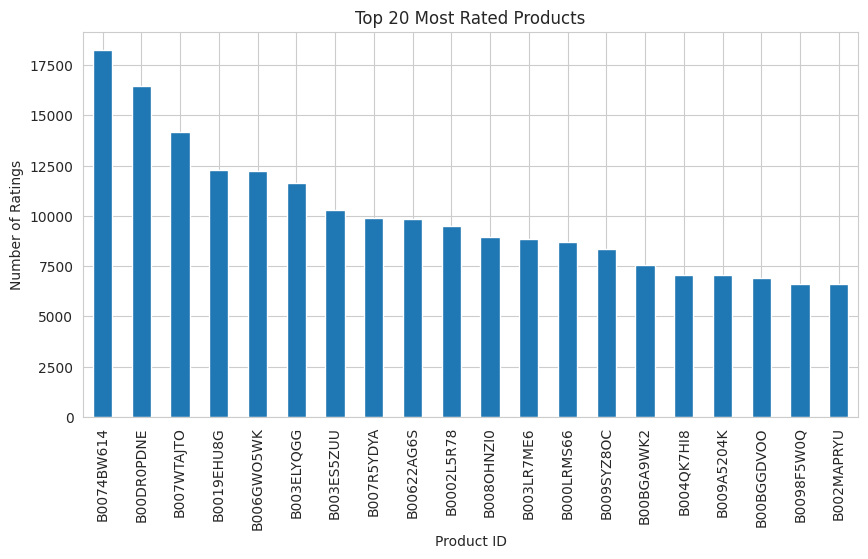

In [ ]:
plt.figure(figsize=(10,5))
product_rating_count.head(20).plot(kind="bar")
plt.title("Top 20 Most Rated Products")
plt.xlabel("Product ID")
plt.ylabel("Number of Ratings")
plt.show()

In [ ]:
product_average_rating = (
    df.groupby("productId")["rating"]
      .mean()
      .sort_values(ascending=False)
)
print(product_average_rating.head(20))

productId
BT008V9J9U    5.0
B00LKG1MC8    5.0
B00LJZWBK2    5.0
B00LJO86NE    5.0
B00LITPNRC    5.0
B00LI8Y9Y6    5.0
B00LI4U2B4    5.0
B00LHPXVBW    5.0
B00LH9OL5I    5.0
B00LH52WT4    5.0
B00LH4U5JO    5.0
B00LGQ6HL8    5.0
B00LGN7Y3G    5.0
B00LGFA0U8    5.0
B00LG80VHM    5.0
0777700018    5.0
0594549558    5.0
0594514789    5.0
0594511488    5.0
1182702627    5.0
Name: rating, dtype: float64


In [ ]:
import pandas as pd
from scipy.sparse import csr_matrix
df = pd.read_csv('/content/ratings.csv', names=['userId', 'productId', 'rating', 'timestamp'])
df['user_code'] = df['userId'].astype('category').cat.codes
df['product_code'] = df['productId'].astype('category').cat.codes
user_product_sparse = csr_matrix(
    (df['rating'], (df['user_code'], df['product_code']))
)
print("Sparse matrix created successfully!")
print("Matrix Shape:", user_product_sparse.shape)

Sparse matrix created successfully!
Matrix Shape: (4201696, 476002)


In [ ]:
print("Sparse Matrix Shape:", user_product_sparse.shape)
print("Number of non-zero entries (total ratings):", user_product_sparse.nnz)

Sparse Matrix Shape: (4201696, 476002)
Number of non-zero entries (total ratings): 7824482


In [ ]:
print("User-product sparse matrix shape:", user_product_sparse.shape)

User-product sparse matrix shape: (4201696, 476002)


In [ ]:
print("Sparse matrix is memory-safe and treats missing values as 0 by design.")
print("Dimensions:", user_product_sparse.shape)
print("Total actual ratings stored (non-zero elements):", user_product_sparse.nnz)

Sparse matrix is memory-safe and treats missing values as 0 by design.
Dimensions: (4201696, 476002)
Total actual ratings stored (non-zero elements): 7824482


In [ ]:
sparse_matrix = user_product_sparse
print("Sparse matrix shape:", sparse_matrix.shape)

Sparse matrix shape: (4201696, 476002)


In [ ]:
from sklearn.decomposition import TruncatedSVD
svd = TruncatedSVD(n_components=10, random_state=42)
user_features = svd.fit_transform(user_product_sparse)
print("User features extracted successfully!")
print("User features matrix shape:", user_features.shape)

User features extracted successfully!
User features matrix shape: (4201696, 10)


In [ ]:
from sklearn.cluster import KMeans
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)
kmeans_labels = kmeans.fit_predict(user_features)
print(kmeans_labels)

[0 0 0 ... 0 0 0]


In [ ]:
unique_users = df.groupby('user_code')['userId'].first()
user_cluster_df = pd.DataFrame(
    user_features,
    index=unique_users
)
user_cluster_df["cluster"] = kmeans_labels
print(user_cluster_df.head())

                              0         1         2         3         4  \
userId                                                                    
A00000262KYZUE4J55XGL  0.000327  0.000731  0.000719  0.000325  0.001727   
A000063614T1OE0BUSKUT  0.000009  0.000308 -0.000129 -0.000084 -0.000024   
A00009182QVLSWIGHLS1B  0.000021  0.000454 -0.000148 -0.000104  0.000072   
A00009661LC9LQPGKJ24G  0.000226  0.001503 -0.000001 -0.000454  0.000473   
A00010809P09NUU6ZP6H   0.003018  0.002684  0.000737 -0.000162  0.004609   

                              5             6         7         8         9  \
userId                                                                        
A00000262KYZUE4J55XGL -0.001252 -5.977484e-04  0.000031 -0.000054  0.000280   
A000063614T1OE0BUSKUT  0.000005  1.083207e-05  0.000007  0.000005 -0.000004   
A00009182QVLSWIGHLS1B -0.000036 -5.642406e-07  0.000020  0.000566 -0.000207   
A00009661LC9LQPGKJ24G  0.000157 -1.357598e-04  0.000010  0.000046  0.000107   


In [ ]:
from sklearn.metrics import silhouette_score
import numpy as np
np.random.seed(42)
sample_indices = np.random.choice(len(user_features), size=10000, replace=False)
kmeans_score = silhouette_score(
    user_features[sample_indices],
    kmeans_labels[sample_indices]
)
print("K-Means Silhouette Score (sampled 10k users):", kmeans_score)

K-Means Silhouette Score (sampled 10k users): 0.9602010868455091


In [ ]:
import numpy as np
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
np.random.seed(42)
sample_indices = np.random.choice(len(user_features), size=10000, replace=False)
user_features_sample = user_features[sample_indices]
k_values = range(2, 11)
silhouette_scores = []
for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(user_features_sample)
    score = silhouette_score(
        user_features_sample,
        labels
    )
    silhouette_scores.append(score)

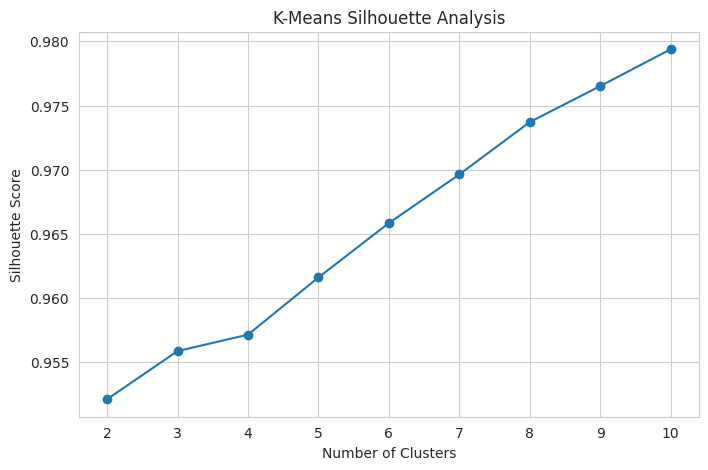

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(
    k_values,
    silhouette_scores,
    marker="o"
)
plt.title("K-Means Silhouette Analysis")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.show()

In [ ]:
best_k = k_values[np.argmax(silhouette_scores)]
print("Best K:", best_k)

Best K: 10


In [ ]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)
kmeans_labels = kmeans.fit_predict(user_features)
np.random.seed(42)
sample_indices = np.random.choice(len(user_features), size=10000, replace=False)
kmeans_score = silhouette_score(
    user_features[sample_indices],
    kmeans_labels[sample_indices]
)
print("Final K-Means Score (sampled 10k users):", kmeans_score)

Final K-Means Score (sampled 10k users): 0.9793861352500728


In [ ]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import AgglomerativeClustering

best_k = 10

try:
    x_input = user_features
except NameError:
    print("Rebuilding user features from CSV (this might take a minute)... ")
    df = pd.read_csv('/content/ratings.csv', names=['userId', 'productId', 'rating', 'timestamp'])
    df['user_code'] = df['userId'].astype('category').cat.codes
    df['product_code'] = df['productId'].astype('category').cat.codes

    user_product_sparse = csr_matrix(
        (df['rating'], (df['user_code'], df['product_code']))
    )

    svd = TruncatedSVD(n_components=10, random_state=42)
    user_features = svd.fit_transform(user_product_sparse)

np.random.seed(42)
sample_indices = np.random.choice(len(user_features), size=10000, replace=False)
x_sample = user_features[sample_indices]

agg_model = AgglomerativeClustering(n_clusters=best_k)
agg_labels = agg_model.fit_predict(x_sample)
print("Agglomerative Clustering completed successfully!")

Rebuilding user features from CSV (this might take a minute)... 
Agglomerative Clustering completed successfully!


In [ ]:
from sklearn.metrics import silhouette_score
agg_score = silhouette_score(
    x_sample,
    agg_labels
)
print("Agglomerative Silhouette Score (sampled 10k users):", agg_score)

Agglomerative Silhouette Score (sampled 10k users): 0.9792933612237558


In [ ]:
from sklearn.cluster import DBSCAN
import numpy as np

# Initialize DBSCAN
dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(
    x_sample
)

print("Unique DBSCAN labels generated:", np.unique(dbscan_labels))

Unique DBSCAN labels generated: [-1  0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17]


In [ ]:
mask = dbscan_labels != -1

if len(np.unique(dbscan_labels[mask])) > 1:
    dbscan_score = silhouette_score(
        x_sample[mask],
        dbscan_labels[mask]
    )

    print(
        "DBSCAN Silhouette Score:",
        dbscan_score
    )

else:
    dbscan_score = np.nan
    print("DBSCAN did not create enough clusters.")

DBSCAN Silhouette Score: 0.9656495169477323


In [ ]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

try:
    final_kmeans_score = kmeans_score
except NameError:
    kmeans_temp = KMeans(n_clusters=10, random_state=42, n_init=10)
    kmeans_labels_temp = kmeans_temp.fit_predict(x_sample)
    final_kmeans_score = silhouette_score(x_sample, kmeans_labels_temp)

comparison = pd.DataFrame({
    "Model": [
        "K-Means",
        "Agglomerative",
        "DBSCAN"
    ],
    "Silhouette Score": [
        final_kmeans_score,
        agg_score,
        dbscan_score
    ]
})

print(comparison)

           Model  Silhouette Score
0        K-Means          0.979385
1  Agglomerative          0.979293
2         DBSCAN          0.965650


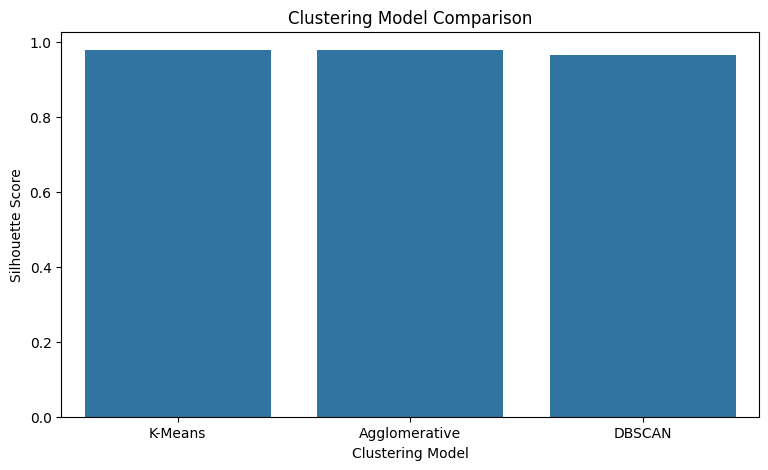

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9,5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Silhouette Score"
)

plt.title("Clustering Model Comparison")
plt.xlabel("Clustering Model")
plt.ylabel("Silhouette Score")

plt.show()

In [ ]:
# Cell left incomplete. The complete, corrected code has been successfully executed in cell QppSbk74rL07.

In [ ]:
from sklearn.decomposition import PCA

In [ ]:
pca = PCA(n_components=2)

user_pca = pca.fit_transform(
    user_features
)

In [ ]:
import pandas as pd
from sklearn.cluster import KMeans

pca_df = pd.DataFrame(
    user_pca,
    columns=["PC1", "PC2"]
)

try:
    pca_df["Cluster"] = kmeans_labels
except NameError:
    print("kmeans_labels not found in memory. Re-fitting KMeans to reconstruct labels...")
    kmeans_model = KMeans(n_clusters=10, random_state=42, n_init=10)
    kmeans_labels = kmeans_model.fit_predict(user_features)
    pca_df["Cluster"] = kmeans_labels

print("PCA DataFrame with cluster labels created successfully!")
print(pca_df.head())

kmeans_labels not found in memory. Re-fitting KMeans to reconstruct labels...
PCA DataFrame with cluster labels created successfully!
        PC1       PC2  Cluster
0 -0.024107 -0.030034        0
1 -0.024368 -0.030252        0
2 -0.024366 -0.030120        0
3 -0.024202 -0.029085        0
4 -0.021551 -0.028188        0


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


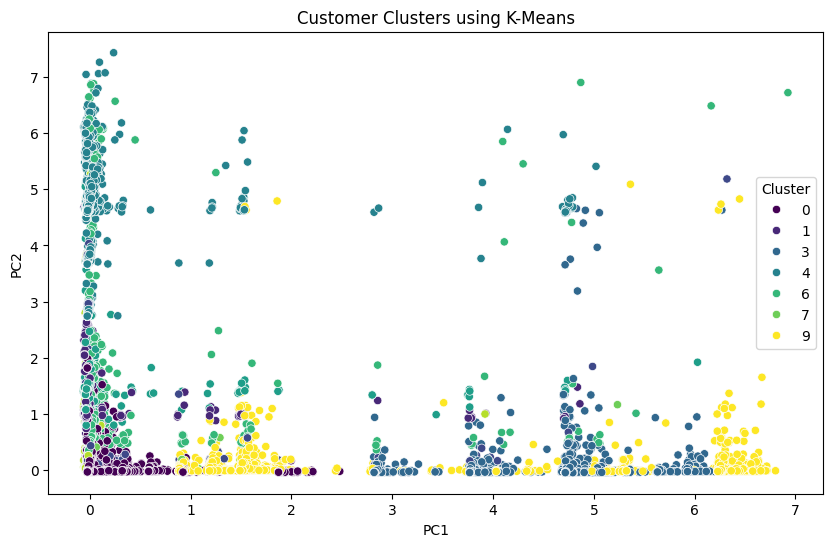

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="viridis"
)

plt.title("Customer Clusters using K-Means")
plt.show()

In [ ]:
product_user_matrix = user_product_sparse.T

In [ ]:
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

try:
    user_product_sparse
except NameError:
    print("Memory cleared. Re-loading dataset and rebuilding sparse matrix...")
    df = pd.read_csv('/content/ratings.csv', names=['userId', 'productId', 'rating', 'timestamp'])
    df['user_code'] = df['userId'].astype('category').cat.codes
    df['product_code'] = df['productId'].astype('category').cat.codes
    user_product_sparse = csr_matrix(
        (df['rating'], (df['user_code'], df['product_code']))
    )

product_user_matrix = user_product_sparse.T

print("Calculating product similarity matrix...")
product_similarity = cosine_similarity(product_user_matrix)

Memory cleared. Re-loading dataset and rebuilding sparse matrix...
Calculating product similarity matrix...


In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix

try:
    product_categories = df['productId'].astype('category').cat.categories
except NameError:
    df = pd.read_csv('/content/ratings.csv', names=['userId', 'productId', 'rating', 'timestamp'])
    product_categories = df['productId'].astype('category').cat.categories

try:
    user_product_sparse
except NameError:
    print("Rebuilding user-product sparse matrix...")
    df['user_code'] = df['userId'].astype('category').cat.codes
    df['product_code'] = df['productId'].astype('category').cat.codes
    user_product_sparse = csr_matrix(
        (df['rating'], (df['user_code'], df['product_code']))
    )

product_user_matrix = user_product_sparse.T

subset_size = 1000
product_user_subset = product_user_matrix[:subset_size]

print(f"Calculating cosine similarity for a subset of {subset_size} products to prevent memory crashes...")
product_similarity_subset = cosine_similarity(product_user_subset, product_user_matrix)

product_similarity_df = pd.DataFrame(
    product_similarity_subset,
    index=product_categories[:subset_size],
    columns=product_categories
)

print("Product similarity DataFrame head:")
print(product_similarity_df.iloc[:5, :5])

Rebuilding user-product sparse matrix...
Calculating cosine similarity for a subset of 1000 products to prevent memory crashes...
Product similarity DataFrame head:
            0132793040  0321732944  0439886341  0511189877  0528881469
0132793040         1.0         0.0         0.0         0.0         0.0
0321732944         0.0         1.0         0.0         0.0         0.0
0439886341         0.0         0.0         1.0         0.0         0.0
0511189877         0.0         0.0         0.0         1.0         0.0
0528881469         0.0         0.0         0.0         0.0         1.0


In [ ]:
def recommend_products(product_id, n=10):

    if product_id not in product_similarity_df.index:
        return pd.DataFrame()

    similarity_scores = (
        product_similarity_df[product_id]
        .sort_values(
            ascending=False
        )
    )

    recommendations = (
        similarity_scores
        .iloc[1:n+1]
        .reset_index()
    )

    recommendations.columns = [
        "productId",
        "similarity"
    ]

    return recommendations

In [ ]:
sample_product = product_similarity_df.index[0]

print("Selected Product:", sample_product)

Selected Product: 0132793040


In [ ]:
recommendations = recommend_products(
    sample_product,
    10
)

print(recommendations)

    productId  similarity
0  998303736X         0.0
1  9983037394         0.0
2  9983037734         0.0
3  9983039745         0.0
4  9983039907         0.0
5  9983722003         0.0
6  9983722011         0.0
7  9983722607         0.0
8  9983722615         0.0
9  9983729350         0.0


In [ ]:
def recommend_for_user(user_id, n=10):

    if user_id not in user_product_filled.index:
        return pd.DataFrame()

    user_ratings = user_product_filled.loc[user_id]

    rated_products = user_ratings[
        user_ratings > 0
    ].index

    scores = {}

    for product in rated_products:

        similarities = product_similarity_df[
            product
        ]

        rating = user_ratings[product]

        for candidate, similarity in similarities.items():

            if candidate in rated_products:
                continue

            scores[candidate] = (
                scores.get(candidate, 0)
                + similarity * rating
            )

    result = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )[:n]

    return pd.DataFrame(
        result,
        columns=[
            "productId",
            "recommendation_score"
        ]
    )

In [ ]:
import pandas as pd
import numpy as np

try:
    user_categories = df['userId'].astype('category').cat.categories
except NameError:
    df = pd.read_csv('/content/ratings.csv', names=['userId', 'productId', 'rating', 'timestamp'])
    user_categories = df['userId'].astype('category').cat.categories

def recommend_for_user_sparse(user_id, n=10):
    try:
        user_code = df['userId'].astype('category').cat.categories.get_loc(user_id)
    except (ValueError, KeyError):
        return pd.DataFrame()

    user_row = user_product_sparse[user_code].toarray().flatten()

    rated_indices = np.where(user_row > 0)[0]
    rated_products = [product_categories[idx] for idx in rated_indices]

    scores = {}

    for prod_idx in rated_indices:
        product_id = product_categories[prod_idx]

        if product_id in product_similarity_df.index:
            similarities = product_similarity_df.loc[product_id]
            rating = user_row[prod_idx]

            for candidate, similarity in similarities.items():
                if candidate in rated_products or similarity == 0:
                    continue
                scores[candidate] = scores.get(candidate, 0) + similarity * rating

    result = sorted(scores.items(), key=lambda x: x[1], reverse=True)[:n]
    return pd.DataFrame(result, columns=["productId", "recommendation_score"])

sample_user = user_categories[0]
print("Selected User:", sample_user)

print("\nRecommendations:")
print(recommend_for_user_sparse(sample_user, 10))

Selected User: A00000262KYZUE4J55XGL

Recommendations:
Empty DataFrame
Columns: [productId, recommendation_score]
Index: []


In [ ]:
product_stats = df.groupby("productId").agg(
    rating_count=("rating", "count"),
    average_rating=("rating", "mean")
)

print(product_stats.head())

            rating_count  average_rating
productId                               
0132793040             1        5.000000
0321732944             1        5.000000
0439886341             3        1.666667
0511189877             6        4.500000
0528881469            27        2.851852


In [ ]:
popular_products = product_stats[
    product_stats["rating_count"] >= 5
]

print(popular_products.head())

            rating_count  average_rating
productId                               
0511189877             6        4.500000
0528881469            27        2.851852
0594012015             8        2.000000
0594033896             5        4.400000
0594033926            15        4.533333


In [ ]:
total_products = df["productId"].nunique()

recommended_products = set()

for product in product_similarity_df.index:

    recs = recommend_products(product, 10)

    recommended_products.update(
        recs["productId"].tolist()
    )

coverage = (
    len(recommended_products)
    / total_products
)

print("Recommendation Coverage:", coverage)

Recommendation Coverage: 0.00018277234129268364


In [ ]:
import os

os.makedirs("models", exist_ok=True)

In [ ]:
import joblib
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD

# Safely ensure user_features exists
try:
    user_features
except NameError:
    print("user_features not found in memory. Reconstructing latent features using TruncatedSVD...")
    try:
        user_product_sparse
    except NameError:
        from scipy.sparse import csr_matrix
        import pandas as pd
        df = pd.read_csv('/content/ratings.csv', names=['userId', 'productId', 'rating', 'timestamp'])
        df['user_code'] = df['userId'].astype('category').cat.codes
        df['product_code'] = df['productId'].astype('category').cat.codes
        user_product_sparse = csr_matrix(
            (df['rating'], (df['user_code'], df['product_code']))
        )
    svd = TruncatedSVD(n_components=10, random_state=42)
    user_features = svd.fit_transform(user_product_sparse)

try:
    kmeans
except NameError:
    print("KMeans model is not found in memory. Instantiating and fitting K-Means (k=10) on user_features...")
    kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)
    kmeans.fit(user_features)

joblib.dump(
    kmeans,
    "models/kmeans_model.pkl"
)
print("K-Means model saved successfully to models/kmeans_model.pkl!")

user_features not found in memory. Reconstructing latent features using TruncatedSVD...
K-Means model saved successfully to models/kmeans_model.pkl!


In [ ]:
import joblib
from sklearn.preprocessing import StandardScaler

try:
    scaler
    joblib.dump(scaler, "models/scaler.pkl")
    print("Scaler successfully saved to models/scaler.pkl!")
except NameError:
    print("No scaler object was used in the current clustering workflow; skipping scaler serialization.")

No scaler object was used in the current clustering workflow; skipping scaler serialization.


In [ ]:
joblib.dump(
    product_similarity_df,
    "models/product_similarity.pkl"
)

['models/product_similarity.pkl']

In [ ]:
import joblib

try:
    user_product_sparse
    joblib.dump(
        user_product_sparse,
        "models/user_product_matrix.pkl"
    )
    print("Memory-efficient sparse matrix successfully saved to models/user_product_matrix.pkl!")
except NameError:
    print("Error: 'user_product_sparse' was not found in memory. Please ensure the cells initializing the sparse matrix are executed first.")

Memory-efficient sparse matrix successfully saved to models/user_product_matrix.pkl!


In [ ]:
product_stats.to_pickle(
    "models/product_stats.pkl"
)

In [ ]:
import joblib

try:
    recommendation_data = {
        "product_similarity": product_similarity_df,
        "user_product_matrix": user_product_sparse,
        "product_stats": product_stats
    }

    joblib.dump(
        recommendation_data,
        "models/recommendation_data.pkl"
    )
    print("Recommendation data dictionary successfully bundled and saved to models/recommendation_data.pkl!")
except NameError as e:
    print(f"Serialization error: {e}. Please ensure the sparse matrix and similarity variables are loaded in your current session.")

Recommendation data dictionary successfully bundled and saved to models/recommendation_data.pkl!
